# Runtime profiling

Visualizes the runs written by `run_profiling.py` to `data/` (one JSON file per (env, policy, budget, seed) run),
collected with `collect_runtimes.sh` and `collect_scaling.sh`.

In [15]:
import json
import sys
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(os.path.abspath('')), "..", "..")))
from examples.plot_style import ANNOTATION_GREY, AREA_ALPHA, MARKERS, PALETTE
from IPython.display import Markdown, display
import numpy as np

DATA_DIR = Path("data")
ENV_ORDER = ["MountainCarContinuous-v0", "Pendulum-v1", "Acrobot-v1"]  # as in collect_runtimes.sh
POLICY_ORDER = ["Random", "Q-Learning", "ActiveLearning", "Entropy"]
# fixed color/marker per policy, so a policy looks the same in every plot
POLICY_STYLE = {p: dict(color=c, marker=m) for p, c, m in zip(POLICY_ORDER, PALETTE, MARKERS)}

# timing categories reported by verigym.create_abstraction, with display labels
TIME_CATEGORIES = {
    "time_simulate": "Simulation",
    "time_policy_update": "Policy update",
    "time_model_construction": "Model construction",
}
# everything needed to obtain the policy; the evaluation itself is excluded
TOTAL_TIME_KEYS = [*TIME_CATEGORIES, "t_stormpy_build"]

# load all runs (non-recursive, so data/quick is ignored)
all_records = [json.loads(f.read_text()) for f in sorted(DATA_DIR.glob("*.json"))]
for r in all_records:
    r["time_total"] = sum(r[k] for k in TOTAL_TIME_KEYS)
print(f"Loaded {len(all_records)} runs from {DATA_DIR}")


## Runtime breakdown per environment

Results of `collect_runtimes.sh`. Bars show the mean over seeds.

In [16]:
POLICY = "Entropy"
BUDGET = 100_000

# seeds per environment for this policy and budget
breakdown = defaultdict(list)
for r in all_records:
    if r["policy"] == POLICY and r["budget"] == BUDGET:
        breakdown[r["env"]].append(r)
envs = [e for e in ENV_ORDER if e in breakdown] + sorted(set(breakdown) - set(ENV_ORDER))
if not envs:
    raise ValueError(f"No runs for policy '{POLICY}' with budget {BUDGET} in {DATA_DIR}, run collect_runtimes.sh")

x = np.arange(len(envs))
bottom = np.zeros(len(envs))

fig, ax = plt.subplots(figsize=(8, 5))
for (key, label), color in zip(TIME_CATEGORIES.items(), PALETTE):
    values = np.array([np.mean([r[key] for r in breakdown[env]]) for env in envs])
    ax.bar(x, values, bottom=bottom, width=0.6, label=label, color=color,
           edgecolor="white", linewidth=2)
    bottom += values

# total runtime above each bar
for xi, total in zip(x, bottom):
    ax.annotate(f"{total:.1f} s", (xi, total), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom")

ax.set_ylim(top=bottom.max() * 1.1)  # room for the total labels
ax.set_xticks(x, [f"{env}\n(n={len(breakdown[env])})" for env in envs])
ax.set_ylabel("Runtime (s)")
ax.set_title(f"Runtime breakdown per environment ({POLICY}, {BUDGET:,} steps)")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e0e0e0")
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'timings.json'

## Scaling with the exploration budget

Results of `collect_scaling.sh`: one JSON file per (env, policy, budget, seed) run in `data/`.

In [20]:
ENV = "MountainCarContinuous-v0"

records = [r for r in all_records if r["env"] == ENV]

# group the seeds of each (policy, budget): runs[policy][budget] -> list of records
runs = defaultdict(lambda: defaultdict(list))
for r in records:
    runs[r["policy"]][r["budget"]].append(r)
policies = [p for p in POLICY_ORDER if p in runs]

def series(policy, key):
    """Budgets and mean/min/max over seeds of `key`, sorted by budget."""
    budgets = sorted(runs[policy])
    values = [np.array([r[key] for r in runs[policy][b]]) for b in budgets]
    return (np.array(budgets), np.array([v.mean() for v in values]),
            np.array([v.min() for v in values]), np.array([v.max() for v in values]))

print(f"Loaded {len(records)} runs for {ENV}: " + ", ".join(f"{p} ({sum(map(len, runs[p].values()))})" for p in policies))


Loaded 16 runs for MountainCarContinuous-v0: Random (4), Q-Learning (4), ActiveLearning (4), Entropy (4)


### Summary table

Means over seeds; ± is the standard deviation over seeds (only shown with more than one seed).

In [21]:
def fmt(values, digits=1):
    values = np.asarray(values, dtype=float)
    s = f"{values.mean():.{digits}f}"
    return s + f" ± {values.std():.{digits}f}" if len(values) > 1 else s

header = ["Policy", "Budget", "Seeds", "Total time (s)", "Simulation (s)", "Policy update (s)",
          "Model constr. (s)", "Explored S", "Explored SA", "Return original"]
rows = []
for p in policies:
    for b in sorted(runs[p]):
        rs = runs[p][b]
        col = lambda k: [r[k] for r in rs]
        rows.append([p, f"{b:,}", str(len(rs)), fmt(col("time_total"), 2), fmt(col("time_simulate"), 2),
                     fmt(col("time_policy_update"), 2), fmt(col("time_model_construction"), 2),
                     fmt(col("explored_states"), 0), fmt(col("explored_state_action_pairs"), 0),
                     fmt(col("mean_reward_original"))])

lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
lines += ["| " + " | ".join(row) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| Policy | Budget | Seeds | Total time (s) | Simulation (s) | Policy update (s) | Model constr. (s) | Explored S | Explored SA | Return original | Return abstraction |
|---|---|---|---|---|---|---|---|---|---|---|
| Random | 1,000 | 1 | 0.03 | 0.02 | 0.00 | 0.01 | 22 | 64 | -11.1 | -4.5 |
| Random | 10,000 | 1 | 0.47 | 0.27 | 0.00 | 0.20 | 48 | 134 | -11.1 | -4.5 |
| Random | 100,000 | 1 | 5.08 | 2.89 | 0.00 | 2.19 | 54 | 154 | -11.1 | -3.7 |
| Random | 1,000,000 | 1 | 48.91 | 27.79 | 0.00 | 21.11 | 68 | 197 | -11.6 | -9.8 |
| Q-Learning | 1,000 | 1 | 0.08 | 0.06 | 0.00 | 0.02 | 17 | 50 | -11.1 | -11.1 |
| Q-Learning | 10,000 | 1 | 0.75 | 0.51 | 0.03 | 0.20 | 46 | 137 | -11.1 | -11.1 |
| Q-Learning | 100,000 | 1 | 8.27 | 5.36 | 0.83 | 2.07 | 53 | 150 | -11.1 | -11.1 |
| Q-Learning | 1,000,000 | 1 | 125.34 | 57.27 | 45.76 | 22.32 | 57 | 168 | -11.1 | -11.1 |
| ActiveLearning | 1,000 | 1 | 0.09 | 0.07 | 0.00 | 0.02 | 17 | 50 | -11.1 | -11.1 |
| ActiveLearning | 10,000 | 1 | 0.76 | 0.52 | 0.04 | 0.20 | 56 | 165 | -11.1 | -11.1 |
| ActiveLearning | 100,000 | 1 | 8.07 | 5.20 | 0.83 | 2.04 | 59 | 173 | -11.1 | -11.1 |
| ActiveLearning | 1,000,000 | 1 | 123.06 | 55.97 | 44.85 | 22.24 | 59 | 173 | -11.1 | -11.1 |
| Entropy | 1,000 | 1 | 0.08 | 0.05 | 0.00 | 0.03 | 11 | 29 | -11.1 | -11.1 |
| Entropy | 10,000 | 1 | 0.68 | 0.39 | 0.06 | 0.22 | 59 | 174 | -11.1 | -11.1 |
| Entropy | 100,000 | 1 | 6.58 | 3.49 | 1.05 | 2.04 | 62 | 184 | -11.1 | -11.1 |
| Entropy | 1,000,000 | 1 | 110.95 | 38.01 | 50.30 | 22.64 | 69 | 205 | -11.1 | -11.1 |

### Coverage and policy value vs. budget

Solid lines (left axis) show the explored state-action pairs; dotted lines (right axis) the mean episode return of the
abstraction's optimal policy on the original environment. Lines show the mean over seeds, bands the min/max over seeds.

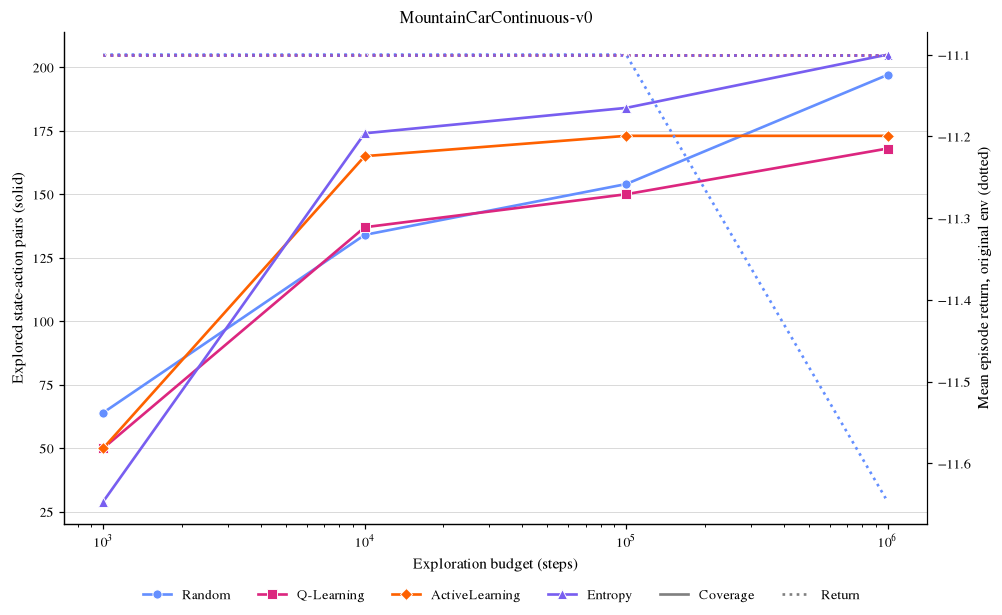

In [22]:
from matplotlib.lines import Line2D

def plot_series(ax, x, mean, lo, hi, style, **kwargs):
    ax.plot(x, mean, color=style["color"], marker=style["marker"], **kwargs)
    if np.any(lo != hi):
        ax.fill_between(x, lo, hi, color=style["color"], alpha=AREA_ALPHA, linewidth=0)

fig, ax_cov = plt.subplots(figsize=(9, 5.5))
ax_val = ax_cov.twinx()

for p in policies:
    style = POLICY_STYLE[p]
    plot_series(ax_cov, *series(p, "explored_state_action_pairs"), style, label=p)
    plot_series(ax_val, *series(p, "mean_reward_original"), style, linestyle=":", markerfacecolor="none")

ax_cov.set_xscale("log")
ax_cov.set_xlabel("Exploration budget (steps)")
ax_cov.set_ylabel("Explored state-action pairs (solid)")
ax_val.set_ylabel("Mean episode return, original env (dotted)")
ax_val.spines["right"].set_visible(True)
ax_val.grid(False)
ax_cov.set_title(ENV)

# legend: color identifies the policy, line style the metric
policy_handles, policy_labels = ax_cov.get_legend_handles_labels()
metric_handles = [Line2D([], [], color=ANNOTATION_GREY, linestyle="-"),
                  Line2D([], [], color=ANNOTATION_GREY, linestyle=":")]
fig.legend(policy_handles + metric_handles, policy_labels + ["Coverage", "Return"],
           loc="outside lower center", ncol=len(policies) + 2, frameon=False)
plt.show()
